<a href="https://colab.research.google.com/github/VioletaNaboy/lab_1/blob/main/%D0%9B%D0%A02_%D0%9D%D0%B0%D0%B1%D0%BE%D0%B9%D1%89%D0%B8%D0%BA%D0%BE%D0%B2%D0%B0_%D0%92%D1%96%D0%BE%D0%BB%D0%B5%D1%82%D0%B0_%D0%A4%D0%86%D0%A2_4_3%D0%B7.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторна робота № 2
## Аналіз і візуалізація даних засобами Seaborn

**Дисципліна:** Комп’ютерні системи візуалізації даних  
**Студент(ка):** Набойщикова Віолета
**Група:** ФІТ 4-3з

**Мета роботи:** опрацювати табличні дані засобами Pandas, дослідити часові ряди та статистичні характеристики і побудувати інформативні графіки за допомогою Seaborn і Matplotlib.

**Середовище:** Google Colab / Jupyter Notebook.  
**Дані:** файл `Museum_Visitors.csv` (фактична назва завантаженого файлу може відрізнятися) та датасет `penguins`.

**Вимоги до виконання:** заповніть порожні кодові комірки, виконайте їх послідовно, збережіть виведені таблиці та графіки. Кожен графік повинен мати зрозумілий заголовок і підписи осей. Не змінюйте формулювання завдань.

## Частина 1. Датасет Museum Visitors

Дані містять місячну відвідуваність музеїв і культурних об’єктів Лос-Анджелеса. У вихідній таблиці — один стовпець із датою та 11 стовпців із кількістю відвідувачів.

| Стовпець | Зміст |
|:--|:--|
| `Month` | Місяць і рік спостереження |
| `America Tropical Interpretive Center` | Кількість відвідувачів центру America Tropical |
| `Avila Adobe` | Відвідувачі історичної будівлі Avila Adobe |
| `Chinese American Museum` | Відвідувачі Китайсько-Американського музею |
| `Gateway to Nature Center` | Відвідувачі центру Gateway to Nature |
| `Firehouse Museum` | Відвідувачі пожежного музею |
| `Hellman Quon` | Відвідувачі історичної будівлі Hellman Quon |
| `IAMLA` | Відвідувачі Італійсько-Американського музею Лос-Анджелеса |
| `Pico House` | Відвідувачі історичної будівлі Pico House |
| `Visitor Center/ El Tranquilo Gallery` | Відвідувачі центру та галереї El Tranquilo |
| `Museum of Social Justice` | Відвідувачі Музею соціальної справедливості |
| `Biscailuz Gallery/ PK Outdoor Exhibit` | Відвідувачі галереї та відкритої експозиції |

**Увага:** відсутнє значення (`NaN`) не обов'язково означає нульову відвідуваність. Деякі об’єкти мають дані лише за частину періоду. Це потрібно враховувати в розрахунках.

### Завдання 1. Імпорт бібліотек

Імпортуйте `pandas`, `numpy`, `matplotlib.pyplot` та `seaborn`. Для роботи в Google Colab за потреби використайте засоби завантаження локального CSV-файлу.

In [19]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files
uploaded = files.upload()

Saving Museum_Visitors.csv to Museum_Visitors.csv


### Завдання 2. Завантаження даних

Завантажте файл **Museum Visitors** у DataFrame `df`. Виведіть перші п’ять рядків таблиці та її розмірність.

In [20]:
df = pd.read_csv('Museum_Visitors.csv')
display(df.head())
print("Розмірність датасету:", df.shape)

,Month,America Tropical Interpretive Center,Avila Adobe,Chinese American Museum,Gateway to Nature Center,Firehouse Museum,Hellman Quon,IAMLA,Pico House,Visitor Center/ El Tranquilo Gallery,Museum of Social Justice,Biscailuz Gallery/ PK Outdoor Exhibit
0,01/01/2014 12:00:00 AM,6602,24778,1581,NaN,4486,0.0,NaN,2204.0,2961.0,NaN,NaN
1,02/01/2014 12:00:00 AM,5029,18976,1785,NaN,4172,0.0,NaN,1330.0,2276.0,NaN,NaN
2,03/01/2014 12:00:00 AM,8129,25231,3229,NaN,7082,70.0,NaN,4320.0,3116.0,NaN,NaN
3,04/01/2014 12:00:00 AM,2824,26989,2129,NaN,6756,250.0,NaN,3277.0,2808.0,NaN,NaN
4,05/01/2014 12:00:00 AM,10694,36883,3676,NaN,10858,135.0,NaN,4122.0,3987.0,NaN,NaN


Розмірність датасету: (85, 12)


### Завдання 3. Первинний аналіз

Визначте типи даних, кількість непорожніх значень у стовпцях та основні описові статистики числових ознак.

In [21]:
print("Типи даних і кількість непорожніх значень:")
df.info()

print("\nОсновні описові статистики числових ознак:")
display(df.describe())

Типи даних і кількість непорожніх значень:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 85 entries, 0 to 84
Data columns (total 12 columns):
 #   Column                                 Non-Null Count  Dtype  
---  ------                                 --------------  -----  
 0   Month                                  85 non-null     object 
 1   America Tropical Interpretive Center   85 non-null     int64  
 2   Avila Adobe                            85 non-null     int64  
 3   Chinese American Museum                85 non-null     int64  
 4   Gateway to Nature Center               32 non-null     float64
 5   Firehouse Museum                       85 non-null     int64  
 6   Hellman Quon                           26 non-null     float64
 7   IAMLA                                  54 non-null     float64
 8   Pico House                             83 non-null     float64
 9   Visitor Center/ El Tranquilo Gallery   45 non-null     float64
 10  Museum of Social Justice         

,America Tropical Interpretive Center,Avila Adobe,Chinese American Museum,Gateway to Nature Center,Firehouse Museum,Hellman Quon,IAMLA,Pico House,Visitor Center/ El Tranquilo Gallery,Museum of Social Justice,Biscailuz Gallery/ PK Outdoor Exhibit
count,85.000000,85.000000,85.000000,32.000000,85.000000,26.000000,54.000000,83.000000,45.000000,37.000000,39.000000
mean,5637.694118,19904.952941,2359.117647,1247.375000,5286.776471,353.461538,882.611111,1329.710843,2634.800000,2125.972973,1088.615385
std,3277.453044,9495.340548,1360.427221,1212.137535,6591.535926,447.043106,507.197681,1832.519767,2055.530871,1954.845497,664.825565
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,3891.000000,17056.000000,1785.000000,0.000000,3858.000000,81.250000,685.000000,177.500000,1769.000000,0.000000,794.000000
50%,5705.000000,20815.000000,2371.000000,1138.000000,4613.000000,180.000000,1020.000000,605.000000,2751.000000,2557.000000,933.000000
75%,6955.000000,25234.000000,2808.000000,1882.500000,5406.000000,458.750000,1202.250000,1597.500000,3323.000000,2911.000000,1306.000000
max,13490.000000,41242.000000,7702.000000,4227.000000,61192.000000,2000.000000,1883.000000,9312.000000,13750.000000,10740.000000,3801.000000


### Завдання 4. Перевірка дублікатів

Обчисліть кількість повністю дубльованих рядків. За наявності дублікатів поясніть, як із ними потрібно вчинити.

In [33]:
duplicates_count = df.duplicated().sum()
print(f"Кількість повністю дубльованих рядків: {duplicates_count}")
print("Пояснення: Якщо дублікати існують, їх потрібно видалити за допомогою методу drop_duplicates(), \nоскільки вони можуть штучно збільшувати показники \nабо повторювати однакові показники відвідуваності без додаткової аналітичної цінності.")

Кількість повністю дубльованих рядків: 0
Пояснення: Якщо дублікати існують, їх потрібно видалити за допомогою методу drop_duplicates(), 
оскільки вони можуть штучно збільшувати показники 
або повторювати однакові показники відвідуваності без додаткової аналітичної цінності.


### Завдання 5. Дослідження пропущених значень

Визначте кількість пропусків для кожного стовпця. Запропонуйте обґрунтований підхід до їх опрацювання. **Не заповнюйте пропуски середнім значенням автоматично:** це може створювати неіснуючі відвідування та спотворювати статистику.

In [32]:
missing_values = df.isnull().sum()
print("Кількість пропусків для кожного стовпця:")
display(missing_values)

print("\nПідхід до опрацювання: Оскільки деякі музеї ще не було відкрито або вони не мали обліку за певні періоди, \nпропуски не можна автоматично замінювати нулями (це штучно знизить середнє) \nчи середнім значенням (це створить неіснуючі відвідування). \nСлід залишати дані як NaN або фільтрувати їх за конкретними об'єктами та періодами під час розрахунків.")

Кількість пропусків для кожного стовпця:


,0
month,0
america_tropical_interpretive_center,0
avila_adobe,0
chinese_american_museum,0
gateway_to_nature_center,53
firehouse_museum,0
hellman_quon,59
iamla,31
pico_house,2
visitor_center_el_tranquilo_gallery,40



Підхід до опрацювання: Оскільки деякі музеї ще не було відкрито або вони не мали обліку за певні періоди, 
пропуски не можна автоматично замінювати нулями (це штучно знизить середнє) 
чи середнім значенням (це створить неіснуючі відвідування). 
Слід залишати дані як NaN або фільтрувати їх за конкретними об'єктами та періодами під час розрахунків.


### Завдання 6. Підготовка назв і дат

Приведіть назви стовпців до зручного для програмування вигляду (нижній регістр, підкреслення замість пробілів і роздільників). Переконайтеся, що немає зайвих підкреслень на початку чи в кінці назв. Перетворіть `Month` на тип дати та перевірте результат.

In [26]:
df.columns = df.columns.str.strip().str.lower().str.replace(r'[\s\-/]+', '_', regex=True)
df.columns = df.columns.str.replace(r'__+', '_', regex=True).str.strip('_')

df['month'] = pd.to_datetime(df['month'])

print("Оновлені назви стовпців:")
print(df.columns.tolist())
print("\nТип стовпця month:", df['month'].dtype)
display(df.head())


Оновлені назви стовпців:
['month', 'america_tropical_interpretive_center', 'avila_adobe', 'chinese_american_museum', 'gateway_to_nature_center', 'firehouse_museum', 'hellman_quon', 'iamla', 'pico_house', 'visitor_center_el_tranquilo_gallery', 'museum_of_social_justice', 'biscailuz_gallery_pk_outdoor_exhibit']

Тип стовпця month: datetime64[ns]


/tmp/ipykernel_2958/4004102160.py:4: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df['month'] = pd.to_datetime(df['month'])


,month,america_tropical_interpretive_center,avila_adobe,chinese_american_museum,gateway_to_nature_center,firehouse_museum,hellman_quon,iamla,pico_house,visitor_center_el_tranquilo_gallery,museum_of_social_justice,biscailuz_gallery_pk_outdoor_exhibit
0,2014-01-01,6602,24778,1581,NaN,4486,0.0,NaN,2204.0,2961.0,NaN,NaN
1,2014-02-01,5029,18976,1785,NaN,4172,0.0,NaN,1330.0,2276.0,NaN,NaN
2,2014-03-01,8129,25231,3229,NaN,7082,70.0,NaN,4320.0,3116.0,NaN,NaN
3,2014-04-01,2824,26989,2129,NaN,6756,250.0,NaN,3277.0,2808.0,NaN,NaN
4,2014-05-01,10694,36883,3676,NaN,10858,135.0,NaN,4122.0,3987.0,NaN,NaN


### Завдання 7. Мінімальна і максимальна відвідуваність у 2018 році

Відберіть записи **за 2018 рік**. Для кожного музею обчисліть мінімальне та максимальне **фактично наявне** місячне значення відвідуваності. Подайте результати у вигляді таблиці. Якщо за цей рік немає даних про певний музей, не підміняйте їх середнім за інші роки.

In [61]:
df_2018 = df[(df['month'].dt.year == 2018)]

museum_cols = [col for col in df.columns if col != 'month']

results_2018 = []
for museum in museum_cols:
    min_val = df_2018[museum].min()
    max_val = df_2018[museum].max()
    results_2018.append({
        'museum': museum,
        'min_visitors_2018': min_val,
        'max_visitors_2018': max_val
    })

df_res_2018 = pd.DataFrame(results_2018)
display(df_res_2018)

,museum,min_visitors_2018,max_visitors_2018
0,america_tropical_interpretive_center,3180.0,5837.0
1,avila_adobe,14718.0,25173.0
2,chinese_american_museum,2078.0,4960.0
3,gateway_to_nature_center,NaN,NaN
4,firehouse_museum,3306.0,8013.0
5,hellman_quon,NaN,NaN
6,iamla,965.0,1601.0
7,pico_house,185.0,2140.0
8,visitor_center_el_tranquilo_gallery,NaN,NaN
9,museum_of_social_justice,2332.0,3686.0


### Завдання 8. Середня відвідуваність

Обчисліть середню місячну кількість відвідувачів для кожного музею **за доступними спостереженнями**. Додатково виведіть кількість місяців, за якими розраховано середнє, щоб можна було правильно порівнювати результати.

In [28]:
museum_cols = [col for col in df.columns if col != 'month']

avg_results = []
for museum in museum_cols:
    valid_data = df[museum].dropna()
    avg_val = valid_data.mean()
    count_months = valid_data.count()
    avg_results.append({
        'museum': museum,
        'average_visitors': avg_val,
        'valid_months_count': count_months
    })

df_avg = pd.DataFrame(avg_results)
display(df_avg)

,museum,average_visitors,valid_months_count
0,america_tropical_interpretive_center,5637.694118,85
1,avila_adobe,19904.952941,85
2,chinese_american_museum,2359.117647,85
3,gateway_to_nature_center,1247.375000,32
4,firehouse_museum,5286.776471,85
5,hellman_quon,353.461538,26
6,iamla,882.611111,54
7,pico_house,1329.710843,83
8,visitor_center_el_tranquilo_gallery,2634.800000,45
9,museum_of_social_justice,2125.972973,37


### Завдання 9. Найменша та найбільша сумарна відвідуваність у 2015 році

Визначте місяці **2015 року** з найменшою та найбільшою сумарною кількістю відвідувачів. Для коректного порівняння використайте однаковий набір музеїв, для яких є дані в усіх 12 місяцях 2015 року, або обґрунтуйте інший спосіб забезпечення порівнюваності.

In [34]:
df_2015 = df[df['month'].dt.year == 2015].copy()

museum_cols = [col for col in df.columns if col != 'month']
valid_museums_2015 = [m for m in museum_cols if df_2015[m].notnull().all()]

df_2015['total_visitors'] = df_2015[valid_museums_2015].sum(axis=1)

min_row = df_2015.loc[df_2015['total_visitors'].idxmin()]
max_row = df_2015.loc[df_2015['total_visitors'].idxmax()]

print(f"Місяць з найменшою сумарною відвідуваністю у 2015 році: {min_row['month'].strftime('%Y-%m')} (Сума: {min_row['total_visitors']})")
print(f"Місяць з найбільшою сумарною відвідуваністю у 2015 році: {max_row['month'].strftime('%Y-%m')} (Сума: {max_row['total_visitors']})")
print(f"Обґрунтування: Використано набір із {len(valid_museums_2015)} музеїв, які мають повні дані за всі 12 місяців 2015 року.")

Місяць з найменшою сумарною відвідуваністю у 2015 році: 2015-02 (Сума: 30771.0)
Місяць з найбільшою сумарною відвідуваністю у 2015 році: 2015-05 (Сума: 73429.0)
Обґрунтування: Використано набір із 7 музеїв, які мають повні дані за всі 12 місяців 2015 року.


### Завдання 10. Сезонне порівняння для Avila Adobe

Для музею **Avila Adobe** обчисліть сумарну кількість відвідувачів **улітку 2018 року (червень–серпень 2018)** і **взимку 2017/2018 (грудень 2017 — лютий 2018)**. Порівняйте отримані значення.

In [35]:
summer_2018 = df[(df['month'] >= '2018-06-01') & (df['month'] <= '2018-08-15')]['avila_adobe'].sum()

winter_17_18 = df[((df['month'] >= '2017-12-01') & (df['month'] <= '2018-02-28'))]['avila_adobe'].sum()

print(f"Сумарна відвідуваність Avila Adobe влітку 2018 року: {summer_2018}")
print(f"Сумарна відвідуваність Avila Adobe взимку 2017/2018 років: {winter_17_18}")
if summer_2018 > winter_17_18:
    print("Порівняння: Влітку 2018 року відвідуваність була вищою, ніж взимку 2017/2018.")
else:
    print("Порівняння: Взимку 2017/2018 років відвідуваність була вищою, ніж влітку 2018.")

Сумарна відвідуваність Avila Adobe влітку 2018 року: 66122
Сумарна відвідуваність Avila Adobe взимку 2017/2018 років: 49322
Порівняння: Влітку 2018 року відвідуваність була вищою, ніж взимку 2017/2018.


### Завдання 11. Кореляційна матриця

Розрахуйте коефіцієнти кореляції для числових стовпців відвідуваності та побудуйте **теплову карту Seaborn**. Збережіть знаки коефіцієнтів (не застосовуйте модуль до всієї матриці) і не включайте до неї технічні стовпці на кшталт номера року.

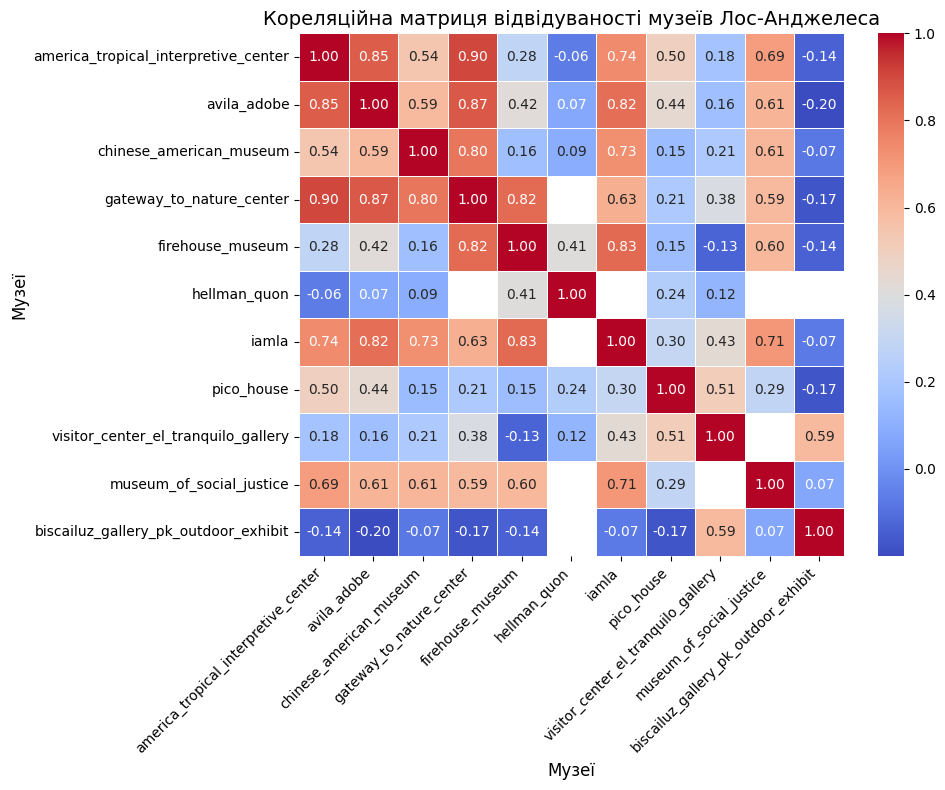

In [36]:
museum_cols = [col for col in df.columns if col != 'month']
corr_matrix = df[museum_cols].corr(numeric_only=True)

plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Кореляційна матриця відвідуваності музеїв Лос-Анджелеса', fontsize=14)
plt.xlabel('Музеї', fontsize=12)
plt.ylabel('Музеї', fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.savefig('correlation_matrix.png')
plt.show()

### Візуалізація відвідуваності засобами Seaborn

Побудуйте чотири графіки за наведеною тематикою. Поясніть у висновках, яку інформацію найкраще відображає кожний тип графіка.

### Завдання 12. Лінійний графік

Побудуйте **лінійний графік** зміни кількості відвідувачів **Avila Adobe** за місяцями. Підпишіть осі й заголовок.

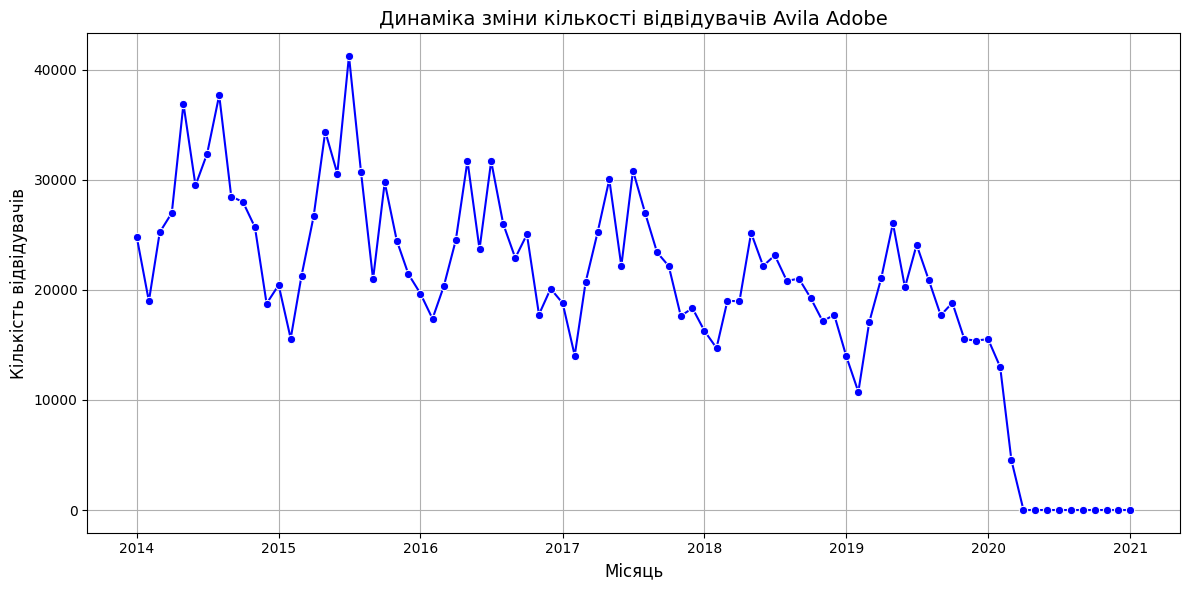

In [38]:
plt.figure(figsize=(12, 6))
sns.lineplot(data=df, x='month', y='avila_adobe', marker='o', color='b')
plt.title('Динаміка зміни кількості відвідувачів Avila Adobe', fontsize=14)
plt.xlabel('Місяць', fontsize=12)
plt.ylabel('Кількість відвідувачів', fontsize=12)
plt.grid(True)
plt.tight_layout()
plt.savefig('avila_adobe_lineplot.png')
plt.show()

### Завдання 13. Діаграма розмаху

Побудуйте **boxplot** для дослідження розподілу місячної відвідуваності **Chinese American Museum** за роками.

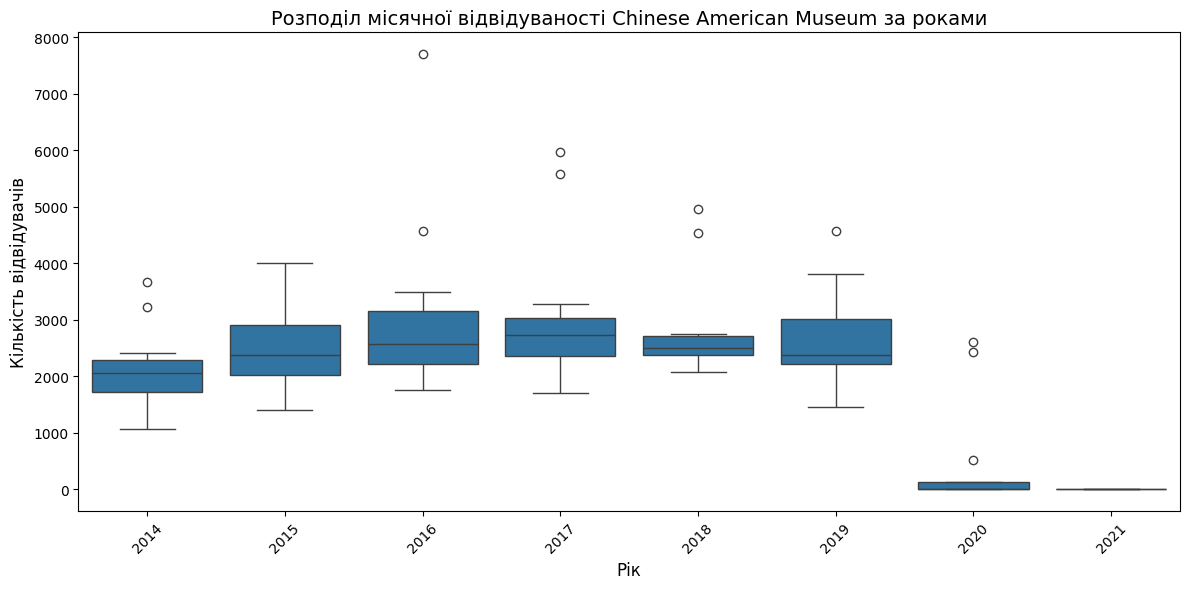

In [39]:
df['year'] = df['month'].dt.year

plt.figure(figsize=(12, 6))
sns.boxplot(data=df, x='year', y='chinese_american_museum')
plt.title('Розподіл місячної відвідуваності Chinese American Museum за роками', fontsize=14)
plt.xlabel('Рік', fontsize=12)
plt.ylabel('Кількість відвідувачів', fontsize=12)
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig('chinese_american_museum_boxplot.png')
plt.show()

### Завдання 14. Гістограма

Побудуйте **гістограму** кількості відвідувачів **Gateway to Nature Center** за місяць. Використайте лише фактично наявні значення: не створюйте штучний пік шляхом заповнення численних пропусків середнім.

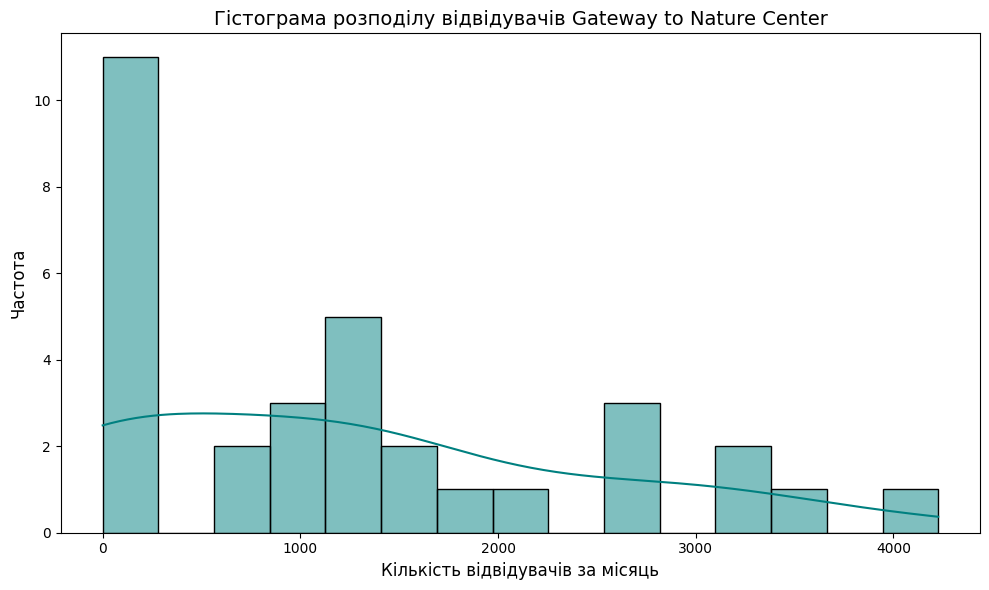

In [40]:
plt.figure(figsize=(10, 6))
sns.histplot(df['gateway_to_nature_center'].dropna(), bins=15, kde=True, color='teal')
plt.title('Гістограма розподілу відвідувачів Gateway to Nature Center', fontsize=14)
plt.xlabel('Кількість відвідувачів за місяць', fontsize=12)
plt.ylabel('Частота', fontsize=12)
plt.tight_layout()
plt.savefig('gateway_to_nature_histogram.png')
plt.show()

### Завдання 15. Стовпчикова діаграма

Побудуйте **barplot** із середньомісячною кількістю відвідувачів для кожного музею. Впорядкуйте музеї за спаданням показника та забезпечте читабельність підписів.

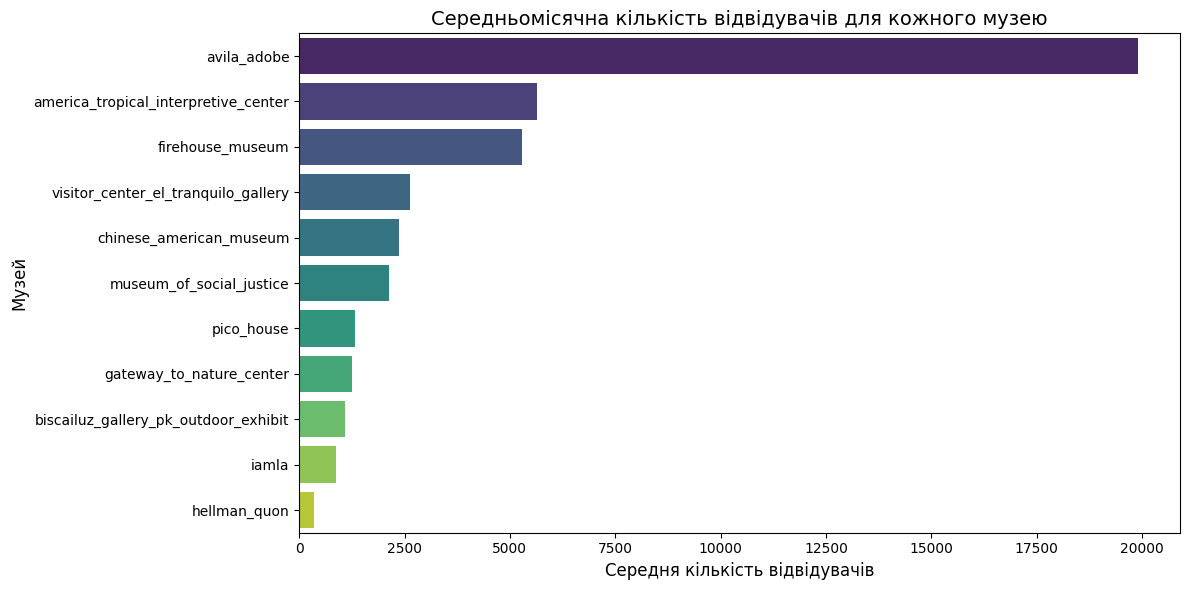

In [41]:
museum_cols = [col for col in df.columns if col not in ['month', 'year']]
mean_visitors = df[museum_cols].mean().sort_values(ascending=False).reset_index()
mean_visitors.columns = ['museum', 'mean_visitors']

plt.figure(figsize=(12, 6))
sns.barplot(data=mean_visitors, x='mean_visitors', y='museum', palette='viridis', hue='museum', legend=False)
plt.title('Середньомісячна кількість відвідувачів для кожного музею', fontsize=14)
plt.xlabel('Середня кількість відвідувачів', fontsize=12)
plt.ylabel('Музей', fontsize=12)
plt.tight_layout()
plt.savefig('mean_visitors_barplot.png')
plt.show()

## Частина 2. Датасет Penguins

Використайте датасет **Penguins** (наприклад, із наборів даних Seaborn). Проведіть його первинне дослідження та створіть **п’ять різних візуалізацій** із використанням Seaborn.

**Вимоги до графіків:** типи графіків **не повинні повторювати приклади з лекції**; добирайте графіки відповідно до типів ознак і дослідницьких запитань. Для кожного графіка зазначте, який зв’язок, розподіл або порівняння він демонструє.

### Завдання 16. Завантаження та огляд Penguins

Завантажте датасет Penguins, виведіть перші п’ять рядків, типи ознак та кількість пропущених значень.

In [42]:
penguins = sns.load_dataset('penguins')
display(penguins.head())

print("\nТипи ознак:")
print(penguins.dtypes)

print("\nКількість пропущених значень:")
display(penguins.isnull().sum())

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,Male
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,Female
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,Female
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,Female



Типи ознак:
species               object
island                object
bill_length_mm       float64
bill_depth_mm        float64
flipper_length_mm    float64
body_mass_g          float64
sex                   object
dtype: object

Кількість пропущених значень:


,0
species,0
island,0
bill_length_mm,2
bill_depth_mm,2
flipper_length_mm,2
body_mass_g,2
sex,11


### Завдання 17. Візуалізація Penguins — графік 1

Оберіть запитання до даних і побудуйте **графік 1** засобами Seaborn. Вкажіть зміст графіка, назву й підписи осей (де доречно). Не повторюйте обрані типи графіків та приклади з лекції.

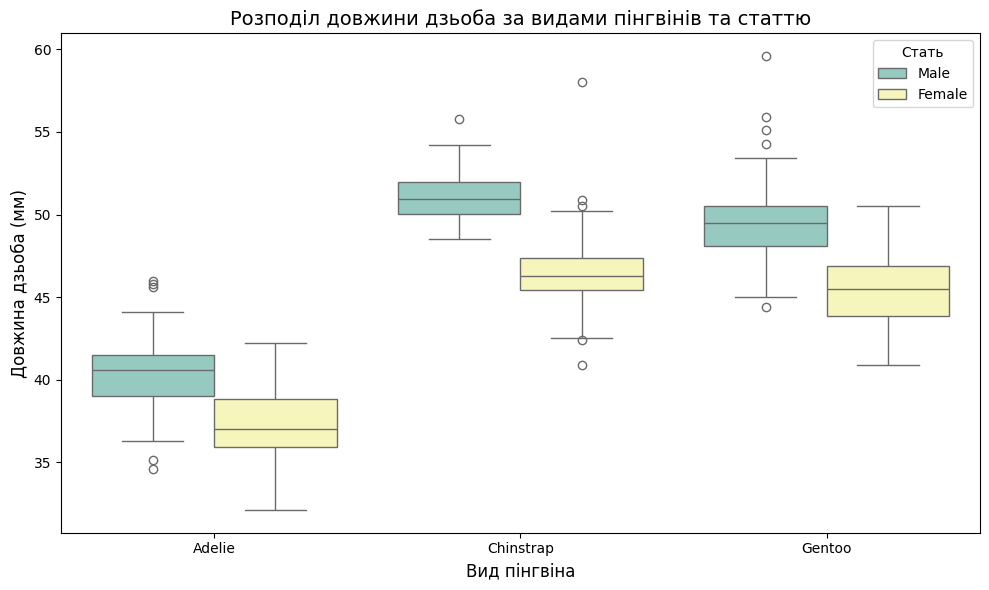

In [43]:
plt.figure(figsize=(10, 6))
sns.boxplot(data=penguins, x='species', y='bill_length_mm', hue='sex', palette='Set3')
plt.title('Розподіл довжини дзьоба за видами пінгвінів та статтю', fontsize=14)
plt.xlabel('Вид пінгвіна', fontsize=12)
plt.ylabel('Довжина дзьоба (мм)', fontsize=12)
plt.legend(title='Стать')
plt.tight_layout()
plt.savefig('penguins_boxplot.png')
plt.show()

### Завдання 18. Візуалізація Penguins — графік 2

Оберіть запитання до даних і побудуйте **графік 2** засобами Seaborn. Вкажіть зміст графіка, назву й підписи осей (де доречно). Не повторюйте обрані типи графіків та приклади з лекції.

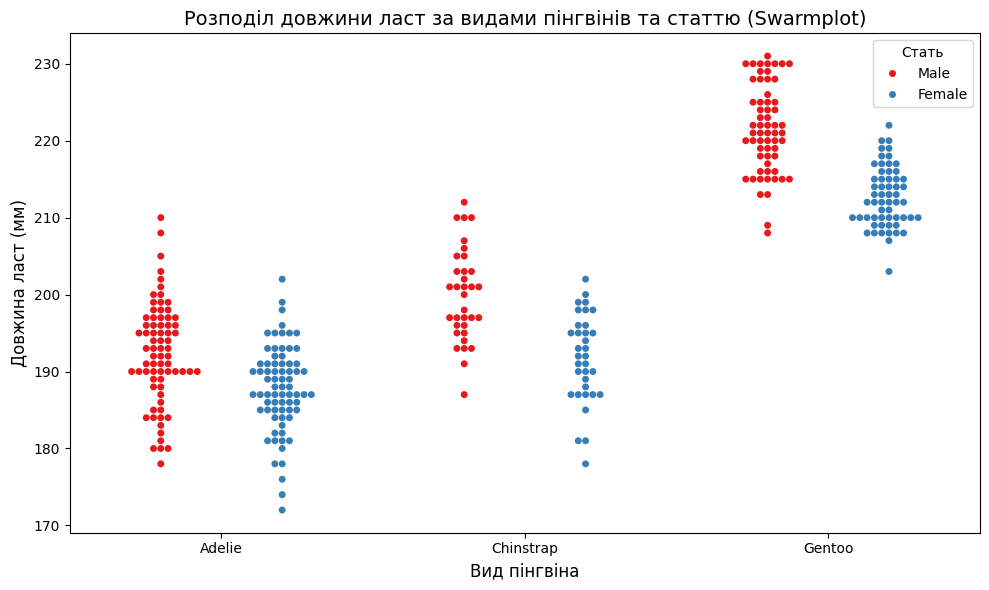

In [44]:
plt.figure(figsize=(10, 6))
sns.swarmplot(data=penguins, x='species', y='flipper_length_mm', hue='sex', dodge=True, palette='Set1')
plt.title('Розподіл довжини ласт за видами пінгвінів та статтю (Swarmplot)', fontsize=14)
plt.xlabel('Вид пінгвіна', fontsize=12)
plt.ylabel('Довжина ласт (мм)', fontsize=12)
plt.legend(title='Стать')
plt.tight_layout()
plt.savefig('penguins_swarmplot.png')
plt.show()

### Завдання 19. Візуалізація Penguins — графік 3

Оберіть запитання до даних і побудуйте **графік 3** засобами Seaborn. Вкажіть зміст графіка, назву й підписи осей (де доречно). Не повторюйте обрані типи графіків та приклади з лекції.

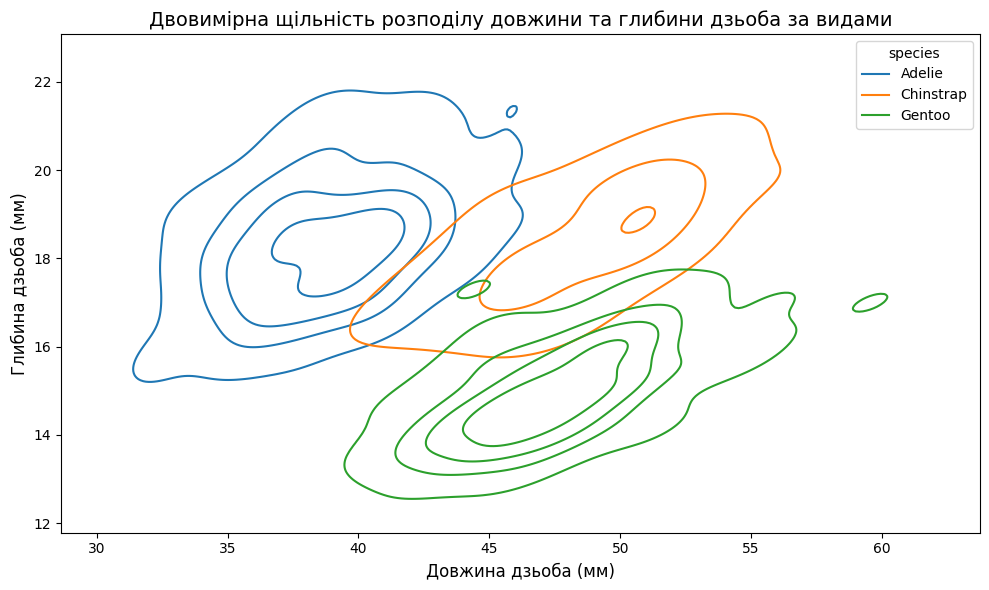

In [45]:
plt.figure(figsize=(10, 6))
sns.kdeplot(data=penguins, x='bill_length_mm', y='bill_depth_mm', hue='species', levels=5, fill=False)
plt.title('Двовимірна щільність розподілу довжини та глибини дзьоба за видами', fontsize=14)
plt.xlabel('Довжина дзьоба (мм)', fontsize=12)
plt.ylabel('Глибина дзьоба (мм)', fontsize=12)
plt.tight_layout()
plt.savefig('penguins_bivariate_kde.png')
plt.show()

### Завдання 20. Візуалізація Penguins — графік 4

Оберіть запитання до даних і побудуйте **графік 4** засобами Seaborn. Вкажіть зміст графіка, назву й підписи осей (де доречно). Не повторюйте обрані типи графіків та приклади з лекції.

/tmp/ipykernel_2958/446152994.py:6: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(title='Вид')


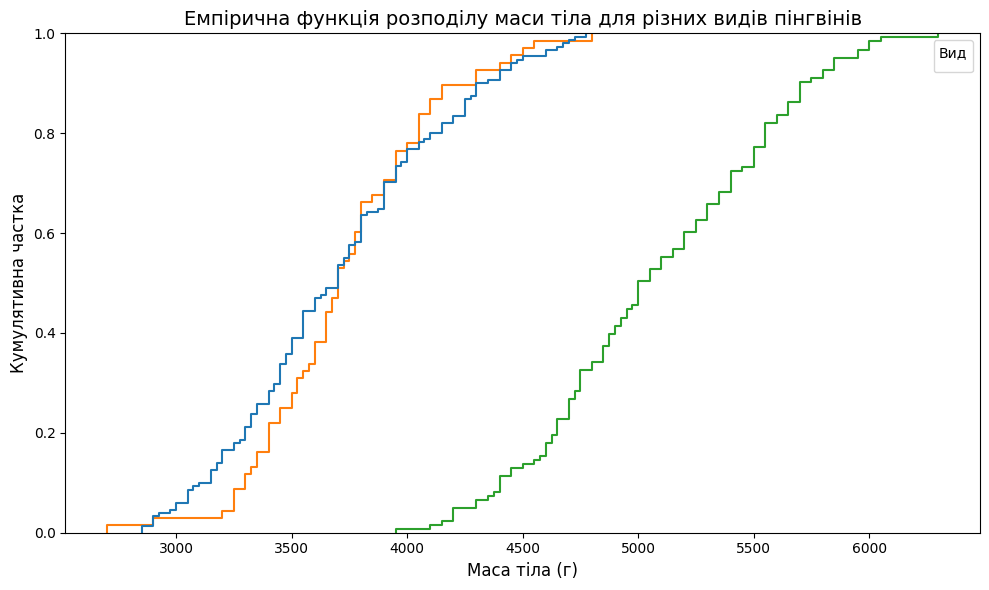

In [46]:
plt.figure(figsize=(10, 6))
sns.ecdfplot(data=penguins, x='body_mass_g', hue='species', stat='proportion')
plt.title('Емпірична функція розподілу маси тіла для різних видів пінгвінів', fontsize=14)
plt.xlabel('Маса тіла (г)', fontsize=12)
plt.ylabel('Кумулятивна частка', fontsize=12)
plt.legend(title='Вид')
plt.tight_layout()
plt.savefig('penguins_ecdf.png')
plt.show()

### Завдання 21. Візуалізація Penguins — графік 5

Оберіть запитання до даних і побудуйте **графік 5** засобами Seaborn. Вкажіть зміст графіка, назву й підписи осей (де доречно). Не повторюйте обрані типи графіків та приклади з лекції.

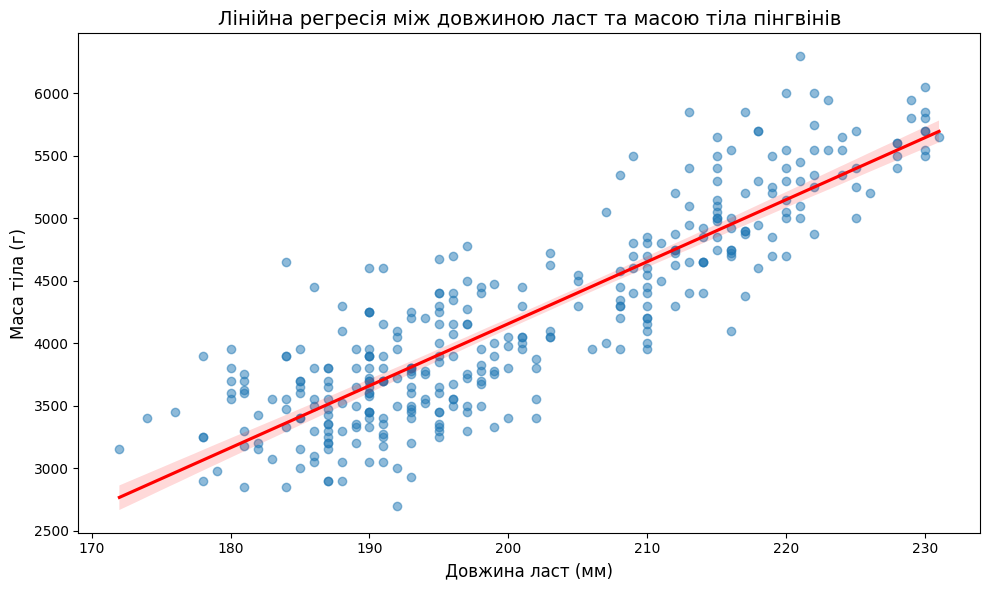

In [47]:
plt.figure(figsize=(10, 6))
sns.regplot(data=penguins, x='flipper_length_mm', y='body_mass_g', scatter_kws={'alpha':0.5}, line_kws={'color':'red'})
plt.title('Лінійна регресія між довжиною ласт та масою тіла пінгвінів', fontsize=14)
plt.xlabel('Довжина ласт (мм)', fontsize=12)
plt.ylabel('Маса тіла (г)', fontsize=12)
plt.tight_layout()
plt.savefig('penguins_regplot.png')
plt.show()

## Висновки

Сформулюйте короткі висновки (5–7 речень):
- які особливості відвідуваності музеїв виявлено;
- як пропущені дані впливають на достовірність розрахунків;
- які закономірності знайдено в даних Penguins;
- які засоби Seaborn були найдоречнішими для Ваших завдань.

**Ваші висновки:**

- Виявлено, що відвідуваність музеїв відрізняється: найбільше відвідувачів у стабільних історичних місцях на кшталт Avila Adobe, тоді як інші об'єкти мають меншу аудиторію або сезонні сплески. Відвідуваність влітку вище, аніж взимку.

- Через пропущені дані (NaN) не можна автоматично підставляти нулі чи середні значення, адже це спотворює реальну картину та штучно створює неіснуючу статистику.

- У даних про пінгвінів виявлено чіткі відмінності між видами за їхніми фізичними розмірами, а також сильну пряму залежність між довжиною ласт і масою тіла.

- Найбільш корисними інструментами бібліотеки Seaborn стали графіки для порівняння розподілів та зв'язків між змінними (boxplot, violinplot, regplot та kdeplot), адже вони дозволили наочно побачити закономірності.